In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Menghubungkan Google Drive dengan Colab.
Untuk menyimpan file project dan menyimpan hasil eksperimen

In [ ]:
!sudo apt-get install python3.10 python3.10-venv python3.10-dev -y
!sudo update-alternatives --install /usr/bin/python3 python3 /usr/bin/python3.10 1
!sudo update-alternatives --config python3

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
python3.10 is already the newest version (3.10.12-1~22.04.13).
python3.10 set to manually installed.
The following additional packages will be installed:
  python3-pip-whl python3-setuptools-whl
The following NEW packages will be installed:
  python3-pip-whl python3-setuptools-whl python3.10-dev python3.10-venv
0 upgraded, 4 newly installed, 0 to remove and 2 not upgraded.
Need to get 2,989 kB of archives.
After this operation, 3,277 kB of additional disk space will be used.
Get:1 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy/main amd64 python3-setuptools-whl all 68.1.2-2~jammy3 [792 kB]
Get:2 http://archive.ubuntu.com/ubuntu jammy-updates/universe amd64 python3-pip-whl all 22.0.2+dfsg-1ubuntu0.7 [1,683 kB]
Get:3 http://archive.ubuntu.com/ubuntu jammy-updates/main amd64 python3.10-dev amd64 3.10.12-1~22.04.13 [508 kB]
Get:4 http://archive.ubuntu.com/ubuntu jammy-updates/univer

Mengatur versi Python stabil & kompatibel
Alasan pakai sudo agar collab berbasis linux sebab jika menggunakan collab langsung tanpa mengatur versi pythone nya akan erorr

In [ ]:
# INSTALL & IMPORT LIBRARY


# --- Install PySpark 3.5.0 dan Java 17 ---
!apt-get update
!apt-get install -y openjdk-17-jdk
!pip install pyspark==3.5.0

# --- Set environment variables ---
import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
os.environ["PYSPARK_PYTHON"] = "python3"

# --- Import Library PySpark & ML ---
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql import functions as F
from pyspark import SparkContext

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator

# --- Library tambahan (EDA) ---
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment ready!")


Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu jammy-cran40/ InRelease
Hit:3 https://r2u.stat.illinois.edu/ubuntu jammy InRelease
Hit:4 http://security.ubuntu.com/ubuntu jammy-security InRelease
Hit:5 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu jammy InRelease
Hit:6 https://ppa.launchpadcontent.net/ubuntugis/ppa/ubuntu jammy InRelease
Hit:7 http://archive.ubuntu.com/ubuntu jammy InRelease
Hit:8 http://archive.ubuntu.com/ubuntu jammy-updates InRelease
Hit:9 http://archive.ubuntu.com/ubuntu jammy-backports InRelease
Fetched 3,917 B in 1s (3,305 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
openjdk-17-jdk is already the newest version (17.0

Mengapa kita menginstal java & pyspark? agar Spark bisa dijalankan tanpa error dependency

Sedangkan set environment variable sendiri digunakan untuk memberitahu spark mengenai lokasi java dan pythone yang digunakan. Tanpa ini spark sering gagal saat start

Import library udah pasti kita ga asing kan jadi langsung ke import untuk algoritma yang kita gunakan yaitu Linear Regresion dan Ramdom Forest Regresion

In [ ]:
# 1 CREATE SPARK SESSION

spark = SparkSession.builder \
    .appName("NYC Taxi Big Data UAS") \
    .master("local[*]") \
    .config("spark.ui.showConsoleProgress","false") \
    .getOrCreate()

spark.range(5).show()


+---+
| id|
+---+
|  0|
|  1|
|  2|
|  3|
|  4|
+---+



Create spark digunakan untuk membuat entry poin spark agar siap memproses data besar seperti data NYC Taxi

DOWNLOAD DATASET

3.A. pemrosesan batch (MapReduce concept)

In [ ]:
!wget https://github.com/DataTalksClub/nyc-tlc-data/releases/download/yellow/yellow_tripdata_2021-01.csv.gz
!gunzip yellow_tripdata_2021-01.csv.gz

--2026-01-25 17:31:06--  https://github.com/DataTalksClub/nyc-tlc-data/releases/download/yellow/yellow_tripdata_2021-01.csv.gz
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/513814948/f6895842-79e6-4a43-9458-e5b0b454a340?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-01-25T18%3A18%3A05Z&rscd=attachment%3B+filename%3Dyellow_tripdata_2021-01.csv.gz&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-01-25T17%3A17%3A15Z&ske=2026-01-25T18%3A18%3A05Z&sks=b&skv=2018-11-09&sig=f%2B%2BJNByW%2FX7iDeVQc0yR2iiL0PgT1x2qlmK2%2F4o1EiM%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc2OTM2NDA2NiwibmJmIjoxNzY5MzYyMjY2L

Mengambil dataset NYC Taxi

In [ ]:
ls -lh

total 121M
drwx------ 5 root root 4.0K Jan 25 17:32 drive/
drwxr-xr-x 1 root root 4.0K Jan 16 14:24 sample_data/
-rw-r--r-- 1 root root 121M Jul 14  2022 yellow_tripdata_2021-01.csv


Untuk mastiin bahwa dataset berhasil di unduh

LOAD DATASET

In [ ]:
df = spark.read.csv(
    "yellow_tripdata_2021-01.csv",
    header=True,
    inferSchema=True
)

df.printSchema()
df.show(5)


root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp (nullable = true)
 |-- tpep_dropoff_datetime: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: integer (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: integer (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)

+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+---

kenapa pakai inframeSchema=True? Agar mengenali integer, Timestamp dan Double

In [ ]:
df.describe().show()

+-------+------------------+------------------+-----------------+------------------+------------------+-----------------+------------------+------------------+------------------+------------------+-------------------+------------------+-------------------+---------------------+------------------+--------------------+
|summary|          VendorID|   passenger_count|    trip_distance|        RatecodeID|store_and_fwd_flag|     PULocationID|      DOLocationID|      payment_type|       fare_amount|             extra|            mta_tax|        tip_amount|       tolls_amount|improvement_surcharge|      total_amount|congestion_surcharge|
+-------+------------------+------------------+-----------------+------------------+------------------+-----------------+------------------+------------------+------------------+------------------+-------------------+------------------+-------------------+---------------------+------------------+--------------------+
|  count|           1271413|           1271

Untuk mengetahui mana Mean,Min,Max, Distribusi awal data. Dan hasillnya terdapat nilai kosong dan perlu preprocessing

3.B. EDA

In [ ]:
df.describe(
    "passenger_count",
    "trip_distance",
    "total_amount"
).show()

+-------+------------------+-----------------+------------------+
|summary|   passenger_count|    trip_distance|      total_amount|
+-------+------------------+-----------------+------------------+
|  count|           1271413|          1369765|           1369765|
|   mean|1.4115082982476976|4.631982077217758|17.474388993744494|
| stddev|1.0598325046055665|393.9042489056104|14.693431734127138|
|    min|                 0|              0.0|            -492.8|
|    max|                 8|        263163.28|           7661.28|
+-------+------------------+-----------------+------------------+



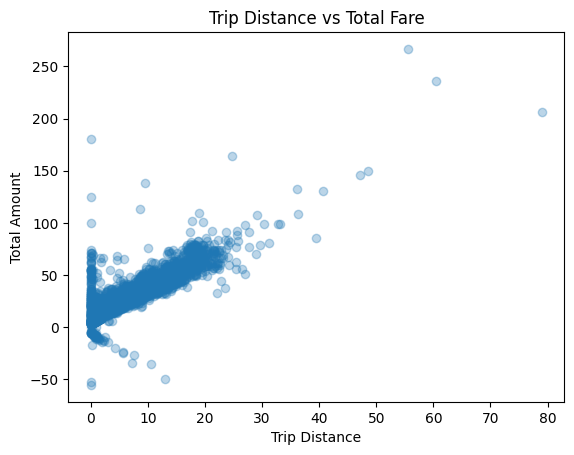

In [ ]:
# Visualisasi
sample_pd = df.select(
    "passenger_count", "trip_distance", "total_amount"
).sample(0.01).toPandas()

plt.scatter(sample_pd["trip_distance"], sample_pd["total_amount"], alpha=0.3)
plt.xlabel("Trip Distance")
plt.ylabel("Total Amount")
plt.title("Trip Distance vs Total Fare")
plt.show()

Melihat hubungan fitur vs target. Dan kenapa hasilnya menyebar? itu disebabkan oleh tarif tidak hanya dipengaruhi oleh jawak karna ada pajak,tip,toll,jumlah penumpang.

PREPROCESSING (CLEAN DATA)

3. C. (casting + handling missing value)

In [ ]:
df_clean = df.select(
    col("passenger_count").cast(DoubleType()),
    col("trip_distance").cast(DoubleType()),
    col("total_amount").cast(DoubleType())
)

# handling missing value
df_clean = df_clean.dropna()

df_clean.describe().show()

+-------+------------------+------------------+------------------+
|summary|   passenger_count|     trip_distance|      total_amount|
+-------+------------------+------------------+------------------+
|  count|           1271413|           1271413|           1271413|
|   mean|1.4115082982476976| 2.695506873061824|16.426071394595684|
| stddev|1.0598325046055665|101.44884518309085|14.107289052638162|
|    min|               0.0|               0.0|            -492.8|
|    max|               8.0|          114328.2|           7661.28|
+-------+------------------+------------------+------------------+



Menghapus data tidak valid, di atas tadi kan ada data yang missing nah disini ia akan dihapus. Kenapa pakai dropna? karna Model Ml tidak dapat membaca NULL dan mencegah erorr training

3. D. MANIPULASI DATA – Spark SQL, CTE, Aggregasi

In [ ]:
df_clean.createOrReplaceTempView("taxi")

spark.sql("""
WITH stats AS (
    SELECT
        passenger_count,
        AVG(trip_distance) AS avg_distance,
        SUM(total_amount) AS total_income,
        MIN(total_amount) AS min_payment,
        MAX(total_amount) AS max_payment
    FROM taxi
    GROUP BY passenger_count
)
SELECT * FROM stats
ORDER BY passenger_count
""").show()


+---------------+------------------+--------------------+-----------+-----------+
|passenger_count|      avg_distance|        total_income|min_payment|max_payment|
+---------------+------------------+--------------------+-----------+-----------+
|            0.0| 2.542446681134471|  438608.26999996114|        0.0|    1155.65|
|            1.0|2.6805497431780125|1.5761777229951017E7|     -252.3|    7661.28|
|            2.0|2.7948183336425947|   2743609.440001915|     -188.3|     523.86|
|            3.0| 2.757641060657794|   736977.1899998623|     -492.8|     600.96|
|            4.0| 2.868198401561832|   281713.8000000021|     -120.3|      400.3|
|            5.0| 2.694099520730803|   512638.6699999351|      -57.3|     311.17|
|            6.0| 2.574517782509266|  408581.75999996654|      -85.8|     351.92|
|            7.0|            11.134|              386.25|      10.32|      106.5|
|            8.0|              1.05|                28.1|       11.8|       16.3|
+---------------

Menganalisis agregasi menggunakan CTE dan hasilnya penumpang lebih banyak -> total pendapatan lebih besar

3. E. RDD: map + reduceByKey

In [ ]:
rdd = df_clean.rdd

map_rdd = rdd.map(lambda x: (x.passenger_count, x.total_amount))
reduce_rdd = map_rdd.reduceByKey(lambda a, b: a + b)

reduce_rdd.collect()


[(0.0, 438608.26999996114),
 (2.0, 2743609.440001915),
 (4.0, 281713.8000000021),
 (6.0, 408581.75999996654),
 (8.0, 28.1),
 (1.0, 15761777.229951017),
 (3.0, 736977.1899998623),
 (5.0, 512638.6699999351),
 (7.0, 386.25)]

Total pendapatan per jumlah penumpang

FEATURE ENGINEERING

In [ ]:
assembler = VectorAssembler(
    inputCols=["passenger_count", "trip_distance"],
    outputCol="features",
    handleInvalid="skip"
)

data_ml = assembler.transform(df_clean)
data_ml.select("features", "total_amount").show(5)

+----------+------------+
|  features|total_amount|
+----------+------------+
| [1.0,2.1]|        11.8|
| [1.0,0.2]|         4.3|
|[1.0,14.7]|       51.95|
|[0.0,10.6]|       36.35|
|[1.0,4.94]|       24.36|
+----------+------------+
only showing top 5 rows



Mengubah fitur -> vector numerik
Kenapa cuma 2 fitur? supaya fokus ke fitur  paling berpengaruh dan mengurangi noise

SPLIT DATA

In [ ]:
train, test = data_ml.randomSplit([0.8, 0.2], seed=42)

Menguji model

4. MODELING (KOMPARASI 2 ALGORITMA)

MODEL 1: LINEAR REGRESSION

In [ ]:
lr = LinearRegression(labelCol="total_amount")
lr_model = lr.fit(train)

lr_pred = lr_model.transform(test)

lr_pred.select(
    "passenger_count",
    "trip_distance",
    "total_amount",
    "prediction"
).show(5)


+---------------+-------------+------------+------------------+
|passenger_count|trip_distance|total_amount|        prediction|
+---------------+-------------+------------+------------------+
|            0.0|          0.0|         0.3|16.289121100755736|
|            0.0|          0.0|         0.8|16.289121100755736|
|            0.0|          0.0|         2.8|16.289121100755736|
|            0.0|          0.0|         3.3|16.289121100755736|
|            0.0|          0.0|         3.3|16.289121100755736|
+---------------+-------------+------------+------------------+
only showing top 5 rows



Untuk mengasumsi hubungan linear
RMSE cukup besar ( akan ditampilkan di bawah)

MODEL 2: RANDOM FOREST REGRESSION

In [ ]:
rf = RandomForestRegressor(
    labelCol="total_amount",
    numTrees=20,
    maxDepth=5
)

rf_model = rf.fit(train)
rf_pred = rf_model.transform(test)

rf_pred.select(
    "passenger_count",
    "trip_distance",
    "total_amount",
    "prediction"
).show(5)

+---------------+-------------+------------+------------------+
|passenger_count|trip_distance|total_amount|        prediction|
+---------------+-------------+------------+------------------+
|            0.0|          0.0|         0.3|13.433782940467433|
|            0.0|          0.0|         0.8|13.433782940467433|
|            0.0|          0.0|         2.8|13.433782940467433|
|            0.0|          0.0|         3.3|13.433782940467433|
|            0.0|          0.0|         3.3|13.433782940467433|
+---------------+-------------+------------+------------------+
only showing top 5 rows



RMSE lebih kecil dari Linear Regression

EVALUASI MODEL (REGRESSION)

In [ ]:
evaluator_rmse = RegressionEvaluator(
    labelCol="total_amount",
    metricName="rmse"
)

evaluator_mse = RegressionEvaluator(
    labelCol="total_amount",
    metricName="mse"
)

print("Linear Regression RMSE:", evaluator_rmse.evaluate(lr_pred))
print("Linear Regression MSE :", evaluator_mse.evaluate(lr_pred))

print("Random Forest RMSE:", evaluator_rmse.evaluate(rf_pred))
print("Random Forest MSE :", evaluator_mse.evaluate(rf_pred))

Linear Regression RMSE: 12.79463181731111
Linear Regression MSE : 163.70260334054979
Random Forest RMSE: 8.51114795158704
Random Forest MSE : 72.43963945380428


RMSE kecil → prediksi mendekati nilai asli
model bagus

In [ ]:
# KOMPARASI MODEL
spark.createDataFrame([
    ("Linear Regression",
     evaluator_rmse.evaluate(lr_pred),
     evaluator_mse.evaluate(lr_pred)),
    ("Random Forest",
     evaluator_rmse.evaluate(rf_pred),
     evaluator_mse.evaluate(rf_pred))
], ["Model", "RMSE", "MSE"]).show()

+-----------------+-----------------+------------------+
|            Model|             RMSE|               MSE|
+-----------------+-----------------+------------------+
|Linear Regression|12.79463181731111|163.70260334054979|
|    Random Forest| 8.51114795158704| 72.43963945380428|
+-----------------+-----------------+------------------+



5. HYPERPARAMETER TUNING

Random Forest + CrossValidator

In [ ]:
paramGrid = ParamGridBuilder() \
    .addGrid(rf.numTrees, [10, 20]) \
    .addGrid(rf.maxDepth, [5, 10]) \
    .build()

cv = CrossValidator(
    estimator=rf,
    estimatorParamMaps=paramGrid,
    evaluator=evaluator_rmse,
    numFolds=3
)

cv_model = cv.fit(train)
cv_pred = cv_model.transform(test)

print("Tuned RF RMSE:", evaluator_rmse.evaluate(cv_pred))


Tuned RF RMSE: 8.410444048712645


Mencari kombinasi terbaik dan RMSE turun setelah tuning

PERBANDINGAN SETELAH TUNING DAN SEBELUM TUNING

In [ ]:
best_rf_model = cv_model.bestModel

In [ ]:
rmse_tuned = evaluator_rmse.evaluate(cv_pred)
print("RMSE Best RF Model:", rmse_tuned)

RMSE Best RF Model: 8.410444048712645


In [ ]:
evaluator_mse = RegressionEvaluator(
    labelCol="total_amount",
    predictionCol="prediction",
    metricName="mse"
)

mse_tuned = evaluator_mse.evaluate(cv_pred)
print("MSE Best RF Model:", mse_tuned)


MSE Best RF Model: 70.73556909652594


In [ ]:
evaluator_r2 = RegressionEvaluator(
    labelCol="total_amount",
    predictionCol="prediction",
    metricName="r2"
)

r2_tuned = evaluator_r2.evaluate(cv_pred)
print("R2 Best RF Model:", r2_tuned)

R2 Best RF Model: 0.5684877376649073


In [ ]:
# Evaluasi model Random Forest sebelum tuning
rmse_before = evaluator_rmse.evaluate(rf_pred)
mse_before = evaluator_mse.evaluate(rf_pred)
r2_before = evaluator_r2.evaluate(rf_pred)

print("RF Before Tuning")
print("RMSE:", rmse_before)
print("MSE :", mse_before)
print("R2  :", r2_before)

RF Before Tuning
RMSE: 8.51114795158704
MSE : 72.43963945380428
R2  : 0.5580922992109674
